# Colab 3 — Survival analysis with lifelines
## Rossi recidivism: weeks until re-arrest

**Original notebook covered:** `4_lifelines_survival` (lifetimes plot, exponential / Weibull MLE, censoring, Kaplan–Meier, Nelson–Aalen, Cox PH, Schoenfeld residuals).

**This notebook uses a different dataset:** `lifelines.datasets.load_rossi` — 432 men released from Maryland prisons; `week` is time to re-arrest, `arrest=1` if the event was observed. That is right-censored survival, not Drosophila time-to-death.

Classical parametric fits still use `scipy.stats` (expon, weibull_min, ECDF) exactly as the lecture did, then we show why those MLE calls ignore censoring.

**Assignment format.** Every **Lecture question** is from `4_lifelines_survival`. The original used Walton fruit flies (miR-137); we use Rossi recidivism. Biology-of-flies questions are answered by translating to this dataset, not by repeating Drosophila trivia.



In [1]:
# Colab setup — run once
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install lifelines
print("Ready. Runtime → Change runtime type → CPU is enough.")



  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 6.2 MB/s eta 0:00:00
Ready. Runtime → Change runtime type → CPU is enough.


In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
from scipy.stats import expon, weibull_min
import lifelines
from lifelines import WeibullFitter, KaplanMeierFitter, NelsonAalenFitter, CoxPHFitter
from lifelines.plotting import plot_lifetimes
from lifelines.statistics import logrank_test
from lifelines.datasets import load_rossi

sns.set_theme(style="whitegrid")
np.random.seed(0)
print("lifelines", lifelines.__version__)



lifelines 0.30.3


## 1. What survival analysis is

We model **time until an event**, with a twist: some times are **censored** (the event has not happened yet when we stop looking). Throwing away censored rows, or treating them as events, biases the survival curve.

Rossi: $T$ = weeks from release until re-arrest; $E=1$ if re-arrested during follow-up, $E=0$ if not (right-censored).



In [3]:
df = load_rossi()
df = df.rename(columns={"week": "T", "arrest": "E"})
display(df.head())
print(df.describe())
print("\nevent rate:", df["E"].mean(), " n =", len(df))
print(df.columns.tolist())



,T,E,fin,age,race,wexp,mar,paro,prio
0,20,1,0,27,1,0,0,1,3
1,17,1,0,18,1,0,0,1,8
2,25,1,0,19,0,1,0,1,13
3,52,0,1,23,1,1,1,1,1
4,52,0,0,19,0,1,0,1,3


                T           E        fin         age        race        wexp  \
count  432.000000  432.000000  432.00000  432.000000  432.000000  432.000000   
mean    45.854167    0.263889    0.50000   24.597222    0.877315    0.571759   
std     12.662293    0.441251    0.50058    6.113375    0.328456    0.495398   
min      1.000000    0.000000    0.00000   17.000000    0.000000    0.000000   
25%     50.000000    0.000000    0.00000   20.000000    1.000000    0.000000   
50%     52.000000    0.000000    0.50000   23.000000    1.000000    1.000000   
75%     52.000000    1.000000    1.00000   27.000000    1.000000    1.000000   
max     52.000000    1.000000    1.00000   44.000000    1.000000    1.000000   

              mar        paro        prio  
count  432.000000  432.000000  432.000000  
mean     0.122685    0.618056    2.983796  
std      0.328456    0.486426    2.896068  
min      0.000000    0.000000    0.000000  
25%      0.000000    0.000000    1.000000  
50%      0.0000

/usr/local/lib/python3.13/dist-packages/lifelines/plotting.py:776: UserWarning: For less visual clutter, you may want to subsample to less than 25 individuals.
  warnings.warn(


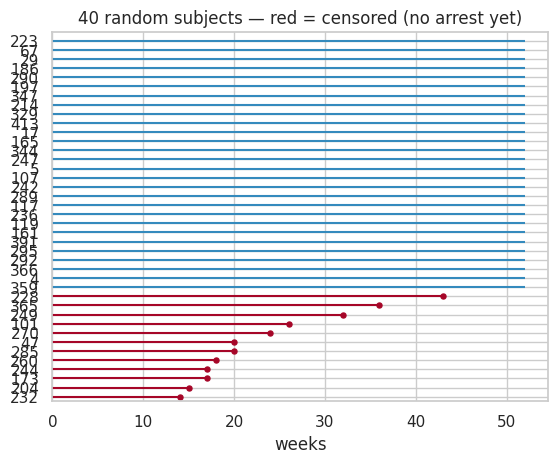

In [4]:
df2 = df.sample(40, random_state=1)
plot_lifetimes(df2["T"], event_observed=df2["E"])
plt.xlabel("weeks")
plt.title("40 random subjects — red = censored (no arrest yet)")
plt.show()



---

**Lecture question**

What's survival analysis about?
What's MiR-137 / Drosophila? (original dataset; we are not using it.)

**Answer**

Survival analysis models **time-to-event** with **censoring**: for some subjects the event has not occurred when observation stops. The object is usually $S(t)=P(T>t)$, the hazard $h(t)$, or a regression for how covariates shift $h(t)$. Ordinary linear regression on $T$ is wrong because (i) $T>0$ and skewed, (ii) censored $T$ are not missing-at-random outcomes you can drop.

The lecture's Walton data: two fly groups, $T$ time to death, $E=0$ if the fly escaped. MiR-137 is a microRNA whose knockdown in *Drosophila* is used as a neurodegeneration model — shorter lifespan in the treatment arm. **We do not analyse flies.** Rossi is the same statistical structure: $T=$ weeks to re-arrest, $E=0$ if not arrested during follow-up. Every tool transfers: KM, Weibull, Cox.

**Critical point.** "Survival" is a metaphor. The event can be death, arrest, divorce, or machine failure. The math cares about $(T,E)$, not biology.



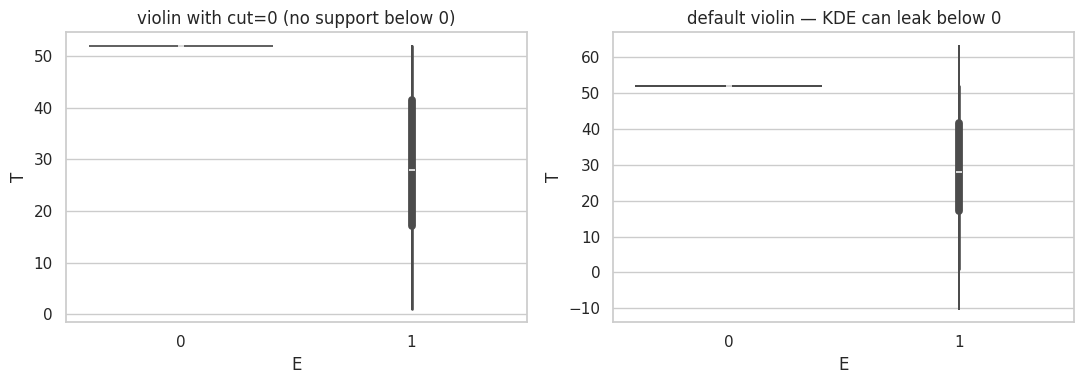

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.violinplot(x="E", y="T", data=df, ax=axes[0], cut=0)
axes[0].set_title("violin with cut=0 (no support below 0)")
sns.violinplot(x="E", y="T", data=df, ax=axes[1])
axes[1].set_title("default violin — KDE can leak below 0")
plt.tight_layout()
plt.show()



---

**Lecture question**

I get negative values in this violin plot even though the data is positive, what gives?

**Answer**

A violin is a **kernel density estimate**. KDEs place Gaussian (or similar) bumps at each point and extend a bandwidth beyond the sample. Positive weeks plus a bandwidth ⇒ density leaking below 0. That is not negative survival; it is a plot that ignores the support. Fixes: `cut=0`, a histogram, or an ECDF/KM curve. Never diagnose "impossible data" from a KDE tail.

The left panel (`cut=0`) is the honest picture; the right panel is the trap the lecture wanted.



## 2. Default parametric story: $T \sim \mathrm{Exp}(\lambda)$

Memorylessness makes the exponential the default *waiting-time* model: hazard is constant. Real human hazards are often a **bathtub** (high infant / early hazard, then flat, then wear-out) — a single exponential cannot do that. Weibull allows a monotone increasing or decreasing hazard; it still cannot do a U-shape alone.



expon MLE loc, scale: 1.0 27.710526315789473


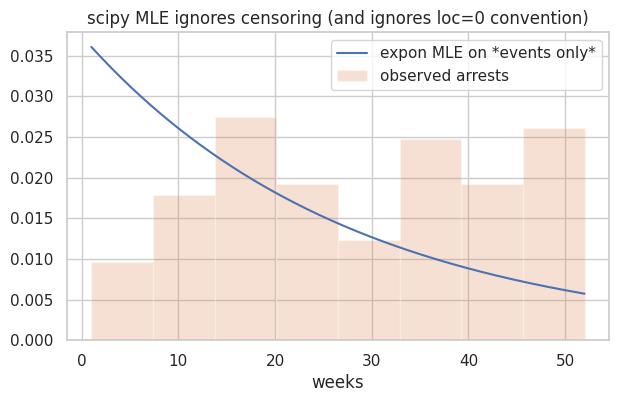

In [6]:
observed = df[df["E"] == 1]
loc, scale = expon.fit(observed["T"])
RV = expon(loc, scale)
print("expon MLE loc, scale:", loc, scale)

x = np.linspace(df["T"].min(), df["T"].max(), 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, RV.pdf(x), label="expon MLE on *events only*")
ax.hist(observed["T"], density=True, bins="auto", alpha=0.25, label="observed arrests")
ax.set_xlabel("weeks"); ax.legend()
ax.set_title("scipy MLE ignores censoring (and ignores loc=0 convention)")
plt.show()



`dist.fit` is maximum likelihood. For an exponential sample $x_i > 0$ with known origin, $\hat\lambda = 1/\bar x$ (or scale $\bar x$ in scipy’s parameterization). Comparing two MLEs on the same uncensored subset: log-likelihood, AIC $= -2\log L + 2k$.

**Censoring in the likelihood.** A right-censored observation at $c$ contributes the survival function $S(c)$, not the density $f(c)$. `scipy.stats` fit methods do not take an event indicator. `lifelines` fitters do.



weibull_min MLE (floc=0): (np.float64(2.0466744090629545), 0, np.float64(32.24412036259996))
loglik events-only  expon / weibull: -492.6866081744653 -465.38519129205054
WeibullFitter (with censoring) rho, lambda: 1.3651415090782515 123.67708708943374


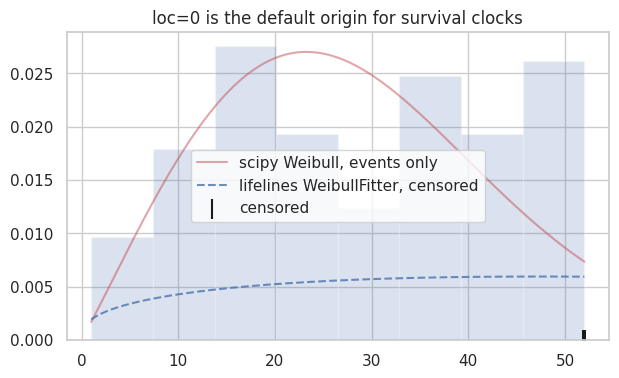

In [7]:
params_w = weibull_min.fit(observed["T"], floc=0)
RVw = weibull_min(*params_w)
print("weibull_min MLE (floc=0):", params_w)

LL_exp = np.sum(expon.logpdf(observed["T"], loc, scale))
LL_wei = np.sum(weibull_min.logpdf(observed["T"], *params_w))
print("loglik events-only  expon / weibull:", LL_exp, LL_wei)

wf = WeibullFitter()
wf.fit(df["T"], event_observed=df["E"])
print("WeibullFitter (with censoring) rho, lambda:", wf.rho_, wf.lambda_)

lam, rho = wf.lambda_, wf.rho_
pdf_ll = (rho / lam) * (x / lam) ** (rho - 1) * np.exp(-(x / lam) ** rho)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, RVw.pdf(x), "r-", alpha=0.5, label="scipy Weibull, events only")
ax.plot(x, pdf_ll, "b--", alpha=0.8, label="lifelines WeibullFitter, censored")
ax.hist(observed["T"], density=True, bins="auto", alpha=0.2)
censored = df[df["E"] == 0]
ax.scatter(censored["T"], np.zeros_like(censored["T"]), marker="|", color="k", s=200, label="censored")
ax.legend()
ax.set_title("loc=0 is the default origin for survival clocks")
plt.show()



---

**Lecture question**

Why is the exponential the default distribution for time until an event?
What's an MLE fit? Show the likelihood of an exponential model given a data vector x.
Why is the exponential not a great model here? Alternatives?
I fit two distributions with MLE. How do I compare them?
How do I take right-censoring into account when fitting a Weibull? Can I do it with scipy.stats? What's the likelihood?
When fitting a Weibull, why is loc=0 the default in survival analysis?
I fit a parametric pdf to survival times. What can I do with it now?

**Answer**

**Why exponential.** Memorylessness: $P(T>s+t\mid T>t)=P(T>s)$. Constant hazard $h(t)=\lambda$. Waiting times for a Poisson process are exponential. It is the *simplest* positive continuous law, hence the default — not because it is often true.

**MLE.** $\hat\theta=\arg\max_\theta \sum_i \log f(x_i;\theta)$. For $\mathrm{Exp}(\lambda)$ on uncensored $x_i>0$ with known origin, $\hat\lambda=1/\bar x$ (scipy's `scale` is $1/\lambda$ if `loc=0`). If `expon.fit` also estimates `loc`, it can slide the support — usually the wrong scientific model.

**Why exponential is poor here.** Recidivism hazard is typically *decreasing* (high early risk, then safer if you lasted). A constant hazard cannot do that. Bathtub hazards (infant mortality + wear-out) are worse. Alternatives: Weibull (monotone hazard, shape $\rho<1$ decreasing, $\rho>1$ increasing), log-normal, log-logistic, piecewise exponential, Cox (semi-parametric).

**Compare MLEs.** Same data: log-likelihood, AIC $=-2\log L+2k$, likelihood-ratio test if nested (exponential is Weibull with $\rho=1$). Different support or different censoring handling ⇒ not comparable. The events-only expon vs events-only Weibull comparison in the cell is valid *as a comparison of two misspecified models*; it is not the right likelihood for Rossi.

**Censoring.** Observation $i$ contributes $f(t_i)^{E_i} S(t_i)^{1-E_i}$. scipy `fit` has no event flag. lifelines `WeibullFitter` maximises that censored likelihood. The two Weibull curves in the plot *must* differ: events-only MLE pretends censored men were arrested at their last week (or drops them) and biases the tail.

**loc=0.** Time is measured from release. A location shift would say "nobody can be arrested before week $\gamma>0$" without evidence. In reliability, loc can be a guaranteed lifetime; here it is almost always 0.

**After fitting.** Median time $S^{-1}(0.5)$, hazard, survival curves, residual checks, simulation of new times, prediction for a new releasee. All of that is only as good as the parametric shape. If KM and Weibull $S(t)$ disagree in the tail, believe KM.



---

**Lecture question**

Assume I know nothing about survival analysis and explain the hazard / survival / density map.
Show the different definitions of the hazard and that they are equivalent.
Explain the bathtub curve. Why does it make the exponential a poor model? Why is Weibull better, and what are its limits?

**Answer**

**The map.** Density $f(t)$: local probability of the event in a small window, not conditional on still being at risk. Survival $S(t)=P(T>t)=1-F(t)$. Hazard $h(t)$: *instantaneous* event rate *given survival so far*. Cumulative hazard $\Lambda(t)=\int_0^t h$. Relationships:
$$
h(t)=\frac{f(t)}{S(t)}=-\frac{S'(t)}{S(t)},\qquad
S(t)=\exp(-\Lambda(t)),\qquad
f(t)=h(t)S(t).
$$
These are equivalent definitions of $h$ (for absolutely continuous $T$): limit of $P(t\le T<t+\Delta\mid T\ge t)/\Delta$, score of $S$, and $f/S$.

**Bathtub.** High hazard just after the origin (infant / early failures / early recidivism), then a flat useful life, then wear-out. Common in humans, machines, and "time since release." A constant exponential hazard is a horizontal line; it cannot be a U. Weibull hazards are monotone ($h(t)\propto t^{\rho-1}$): decreasing *or* increasing, never both. Mixture of Weibulls or a piecewise/spline hazard can U-shape; Cox leaves $h_0(t)$ unspecified and can follow a bathtub in the baseline.

**Criticism.** Fitting Weibull because "it is more flexible than exponential" is still a strong shape bet. Always overlay KM.



## 3. Nonparametric survival: ECDF vs Kaplan–Meier

Naive $1-\mathrm{ECDF}$ on *everyone*, treating censored times as events, **underestimates** survival (you pretend people arrested-at-censoring-time). Variance in the tail is also wrong because you have drained the risk set too fast.

**Kaplan–Meier** is the product-limit MLE of a discrete survival function: at each death time $t_i$, multiply by $1 - d_i / n_i$. Censored subjects leave the risk set without a death.



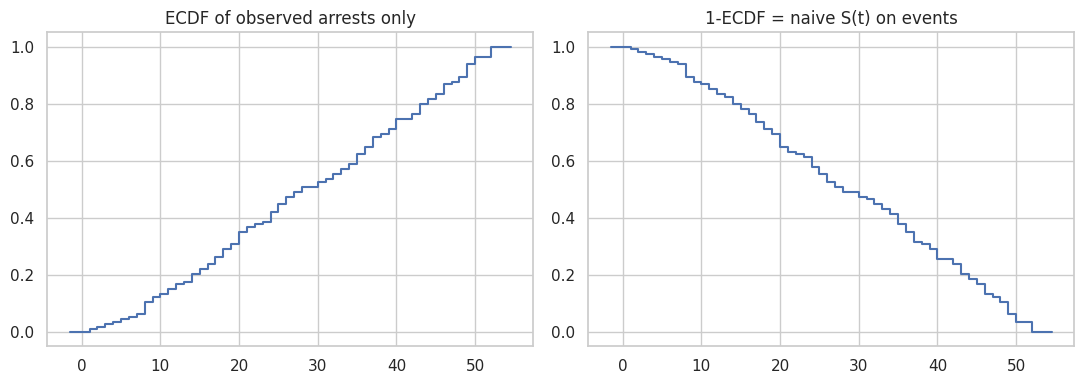

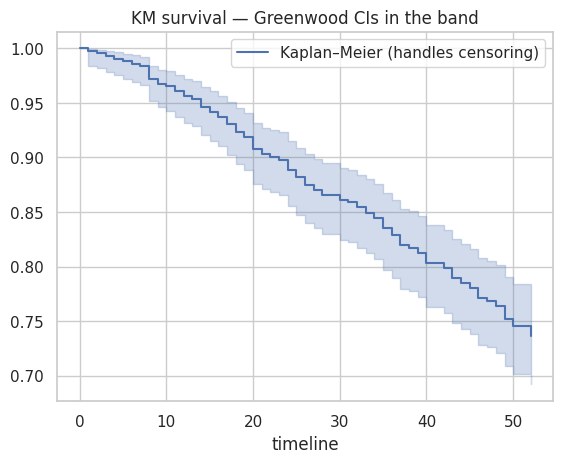

          Kaplan–Meier (handles censoring)
timeline                                  
0.0                               1.000000
1.0                               0.997685
2.0                               0.995370
3.0                               0.993056
4.0                               0.990741


In [8]:
ecdf = ss.ecdf(observed["T"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ecdf.cdf.plot(ax=axes[0]); axes[0].set_title("ECDF of observed arrests only")
ecdf.sf.plot(ax=axes[1]); axes[1].set_title("1-ECDF = naive S(t) on events")
plt.tight_layout()
plt.show()

kmf = KaplanMeierFitter()
kmf.fit(df["T"], df["E"], label="Kaplan–Meier (handles censoring)")
ax = kmf.plot_survival_function()
ax.set_title("KM survival — Greenwood CIs in the band")
plt.show()
print(kmf.survival_function_.head())



---

**Lecture question**

What's wrong with the naive estimator of the survival function (1-ECDF treating censoring as failure)? Mention underestimation and variance in the tail.
What's the Kaplan–Meier estimator and why is it better?
Sketch why KM is the MLE of a discrete survival function given failure times and counts.

**Answer**

Naive $1-\mathbb{F}_n$ that codes censored times as events **underestimates** $S(t)$: you pretend men who were still free were arrested at last contact. Dropping censored rows altogether **overestimates** early survival (you keep only people who failed, a selected sample) and still mishandles the tail. In the tail the risk set is small; pretending censorings are deaths drains $n_i$ too fast and makes variance look smaller than it is.

**KM.** At ordered event times $t_i$ with $d_i$ events and $n_i$ at risk,
$$
\hat S(t)=\prod_{t_i\le t}\Bigl(1-\frac{d_i}{n_i}\Bigr).
$$
Censorings reduce $n$ at the next time but do not multiply a death factor. That is the nonparametric MLE for a discrete hazard on the observed event grid: the likelihood is $\prod_i h_i^{d_i}(1-h_i)^{n_i-d_i}$, maximised at $\hat h_i=d_i/n_i$, and $S$ is the product of $1-h$.

**Criticism.** KM is silent about covariates and can be noisy in the tail ($n_i$ small). It is still the reference curve every parametric model must beat.



**KM confidence intervals in lifelines:** Greenwood’s variance for $\hat S(t)$, often on the $\log(-\log \hat S)$ scale so the interval stays in $(0,1)$. That transform is the delta-method map $g(s)=\log(-\log s)$. Intervals between death times are not independent ($d_i$ changes $n_{i+1}$); Greenwood still works asymptotically via a martingale CLT.

**Why $\log(-\log x)$?** It sends (0,1) to $\mathbb{R}$ and stretches the tails so a Normal approximation is less likely to cross 0 or 1.



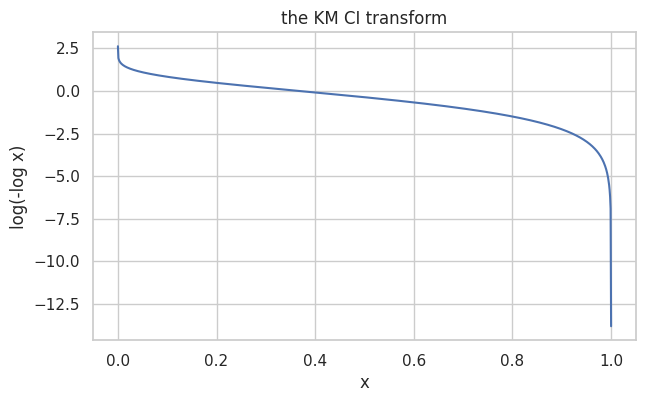

In [9]:
z = np.linspace(1e-6, 1 - 1e-6, 1000)
plt.figure(figsize=(7, 4))
plt.plot(z, np.log(-np.log(z)))
plt.xlabel("x"); plt.ylabel("log(-log x)")
plt.title("the KM CI transform")
plt.grid(True)
plt.show()



---

**Lecture question**

How do they calculate the CIs in KaplanMeierFitter? Greenwood, log(-log), delta method.
Why the log(-log) transform? (figure above)
Explain the delta method.
Derive Greenwood from first principles (delta method). The intervals aren't independent: handwave with the martingale CLT.

**Answer**

Greenwood: $\widehat{\mathrm{Var}}(\hat S(t))=\hat S(t)^2 \sum_{t_i\le t} \frac{d_i}{n_i(n_i-d_i)}$. A Normal interval $\hat S\pm z\sqrt{\widehat{\mathrm{Var}}}$ can leave $(0,1)$. lifelines (and most software) uses a **log-log** transform: set $\hat\theta=\log(-\log\hat S)$, apply the delta method to get $\widehat{\mathrm{Var}}(\hat\theta)$, form a Normal interval on $\theta$, map back with $S=\exp(-\exp(\theta))$. That interval stays in $(0,1)$.

**Why log(-log).** $g(s)=\log(-\log s)$ sends (0,1) onto $\mathbb{R}$ and stretches values near 0 and 1, where a raw Normal is worst. The figure is $g(s)$: vertical asymptotes at 0 and 1.

**Delta method.** If $\sqrt n(\hat\psi-\psi)\to N(0,\sigma^2)$ and $g$ is differentiable at $\psi$, then $\sqrt n(g(\hat\psi)-g(\psi))\to N(0,\sigma^2 g'(\psi)^2)$. Apply to $g(s)=\log(-\log s)$.

**Greenwood sketch.** Treat $\hat h_i=d_i/n_i$ as approximately independent with variance $h_i(1-h_i)/n_i$. $\log\hat S=\sum_{t_i\le t}\log(1-\hat h_i)$. Delta method: $\mathrm{Var}(\log\hat S)\approx\sum \frac{h_i}{n_i(1-h_i)}$, hence $\mathrm{Var}(\hat S)\approx \hat S^2$ times that sum. The $\hat h_i$ are *not* independent ($d_i$ changes $n_{i+1}$). A counting-process martingale CLT still gives the same asymptotic variance — that is the honest justification, and why we do not need a full dependent-delta-method nightmare in this course.

**Criticism.** Greenwood intervals are too narrow in the far tail. Look at $n_i$, not only at the pretty band.



## 4. Cumulative hazard: Nelson–Aalen

Hazard $h(t) = f(t)/S(t) = -S'(t)/S(t)$. Cumulative hazard $\Lambda(t)=\int_0^t h$. **Nelson–Aalen** estimates $\Lambda$ directly (sum $d_i/n_i$). **KM** estimates $S$. They are linked by $S = \exp(-\Lambda)$ in continuous time, but $-\log(\mathrm{KM})$ is *not* identical to NA: Jensen / transformation bias. Use NA if $\Lambda$ is the target; KM if $S$ is the target.



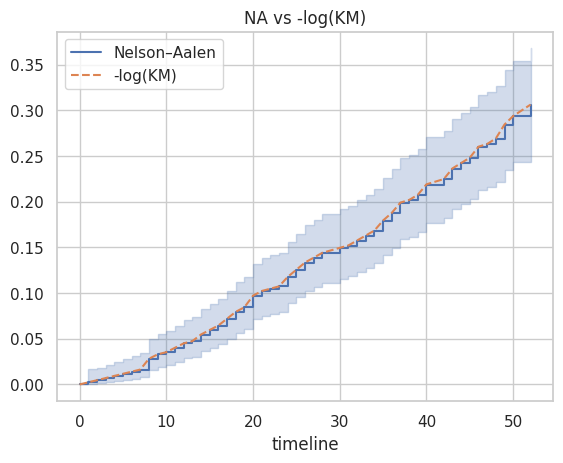

In [10]:
naf = NelsonAalenFitter()
naf.fit(df["T"], df["E"], label="Nelson–Aalen")
ax = naf.plot_cumulative_hazard()
ax.plot(kmf.survival_function_.index,
        -np.log(kmf.survival_function_.iloc[:, 0].clip(lower=1e-12)),
        ls="--", label="-log(KM)")
ax.legend()
ax.set_title("NA vs -log(KM)")
plt.show()



---

**Lecture question**

Compare Nelson–Aalen and Kaplan–Meier. When should I use which?
If I want cumulative hazard, why not just take -log(KM)? Mention change-of-variable bias and Jensen.

**Answer**

KM estimates $S$; NA estimates $\Lambda$ by $\hat\Lambda(t)=\sum_{t_i\le t} d_i/n_i$. In continuous time $S=e^{-\Lambda}$, so they are two views of one object. Use KM to report "fraction still free at week 20." Use NA to report cumulative hazard, Aalen additive models, or residual processes.

**Why not $-\log(\mathrm{KM})$.** For a nonlinear $g$, $g(\mathbb{E}[\hat S])\neq \mathbb{E}[g(\hat S)]$. Jensen: $-\log$ is convex, so $-\log(\hat S)$ is biased for $-\log(S)$ even if $\hat S$ is unbiased for $S$ (and KM is only asymptotically unbiased). NA estimates $\Lambda$ directly and is the MLE in the same discrete-hazard model for the cumulative sum of $\hat h_i$. They are close for large $n_i$ and diverge when $\hat S$ is noisy. The overlay in the plot is the check: if they disagree a lot, you are in the small-risk-set regime.

**Criticism.** Neither uses covariates. If `fin` matters, a single NA curve is an average of two hazards.



## 5. Two groups and a log-rank test

`fin` is financial aid after release (0/1). If KM curves separate, test with **log-rank** (does not need proportional hazards to be a valid *test of equality of survival curves*, but power is best under PH). If curves **cross**, PH is already implausible for a Cox model.



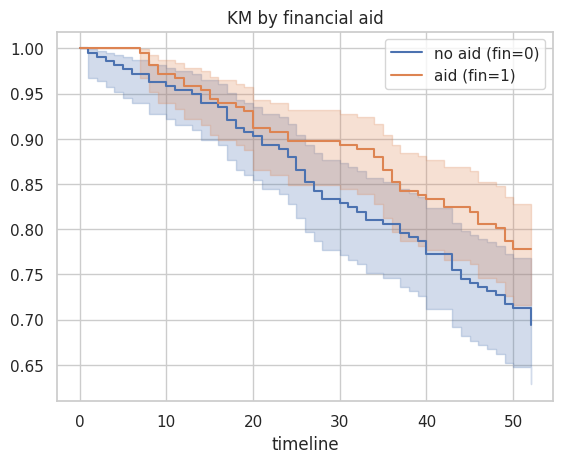

In [11]:
kmf0 = KaplanMeierFitter()
kmf1 = KaplanMeierFitter()
ax = kmf0.fit(df.loc[df["fin"] == 0, "T"], df.loc[df["fin"] == 0, "E"], label="no aid (fin=0)").plot_survival_function()
kmf1.fit(df.loc[df["fin"] == 1, "T"], df.loc[df["fin"] == 1, "E"], label="aid (fin=1)").plot_survival_function(ax=ax)
ax.set_title("KM by financial aid")
plt.show()

res = logrank_test(
    df.loc[df["fin"] == 0, "T"], df.loc[df["fin"] == 1, "T"],
    event_observed_A=df.loc[df["fin"] == 0, "E"],
    event_observed_B=df.loc[df["fin"] == 1, "E"],
)
res.print_summary()



---

**Lecture question**

Analyze this figure. What's the next step? Mention the log-rank test and Cox regression.

**Answer**

If the two KM curves separate and do not cross, there is visual evidence of a `fin` effect: aid associated with higher survival (lower recidivism). The **log-rank test** is the default two-sample test: it is a weighted sum of (observed−expected) events over time, hypergeometric under the null of equal hazards. It does not require PH to be a valid level-α test of equal survival curves, but it is most powerful under PH. If the curves **cross**, log-rank can be insignificant while early and late effects cancel — look at the plot, not only the p-value.

**Next step.** If we want an effect size adjusted for age, priors, etc., fit **Cox**. If PH is implausible (crossing KM), do not blindly report one hazard ratio. Stratify or use time interactions.

**Criticism.** `fin` is not a randomized treatment in Rossi in the sense of a modern RCT (it is a famous observational teaching dataset). A log-rank p-value is not 'aid works'.



## 6. Cox proportional hazards

Hazard: instantaneous risk of the event given survival so far. Cox:

$$
h(t \mid x) = h_0(t)\, \exp(x^\top \beta)
$$

**Semi-parametric:** $h_0(t)$ is unspecified; $\beta$ is estimated from the **partial likelihood** — at each event, the probability that it was this person among those still at risk. There is **no intercept**: $e^{\beta_0}$ would be absorbed into $h_0$.

**PH assumption:** hazard *ratios* are constant over time. Crossing KM curves ⇒ the ratio cannot be constant. Real-life PH failures: surgical mortality (early spike then lower hazard than medical management), time-limited treatment effects.

Media “twice the risk” headlines are usually hazard ratios from Cox-type models — they are not risk differences and they assume PH.

**Concordance (C-index):** $P(\text{predicted risk higher for the one who fails first})$. 0.5 is coin-flip; $\gtrsim 0.7$ is often called decent in medical scoring, context-dependent.



In [12]:
cox_df = load_rossi()  # original names: week, arrest
cph = CoxPHFitter()
cph.fit(cox_df, duration_col="week", event_col="arrest")
cph.print_summary()



<lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
             duration col = 'week'
                event col = 'arrest'
      baseline estimation = breslow
   number of observations = 432
number of events observed = 114
   partial log-likelihood = -658.75
         time fit was run = 2026-09-20 07:38:06 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
fin       -0.38      0.68      0.19           -0.75           -0.00                0.47                1.00
age       -0.06      0.94      0.02           -0.10           -0.01                0.90                0.99
race       0.31      1.37      0.31           -0.29            0.92                0.75                2.50
wexp      -0.15      0.86      0.21           -0.57            0.27                0.57                1.30
mar       -0.43      0.65      0.38           -1.18            0.31                0.31                1.37
paro      -0.08      0.92      0.20           -0.47            0.30                0.63                1.35
prio       0.09      1.10      0.03            0.04            0.15                1.04                1.16

           cmp to     z      p  -log2(p)
covariate                               
fin          0.00 -1.98   0.05      4.40
age          0.00 -2.61   0.01      6.79
race         0.00  1.02   0.31      1.70
wexp         0.00 -0.71   0.48      1.06
mar          0.00 -1.14   0.26      1.97
paro         0.00 -0.43   0.66      0.59
prio         0.00  3.19 <0.005      9.48
---
Concordance = 0.64
Partial AIC = 1331.50
log-likelihood ratio test = 33.27 on 7 df
-log2(p) of ll-ratio test = 15.37

---

**Lecture question**

Explain the Cox PH model. Start from what hazard means. Why is it semi-parametric? Partial likelihood: why does it look like that? Probability of failure in a small dt. Why no intercept?
Hazard ratios in media headlines — mock examples.
Assumptions of Cox. Why do crossing KM curves violate PH? Real-life examples where PH fails.
Explain this lifelines output. How do you calculate concordance? What's a good score?

**Answer**

Hazard $h(t\mid x)$ is the instantaneous arrest rate given still free, for a man with covariates $x$. Cox:
$$
h(t\mid x)=h_0(t)\,e^{x^\top\beta}.
$$
**Semi-parametric:** $h_0$ is an infinite-dimensional nuisance; $\beta$ is finite. We never specify whether the baseline is bathtub, Weibull, or wild.

**Partial likelihood.** In $[t,t+dt]$, $P(\text{event for }i)\approx h_i(t)\,dt$. Conditional on *someone* in the risk set $R(t)$ failing,
$$
P(i\text{ failed}\mid \text{one failure})=\frac{e^{x_i\beta}}{\sum_{j\in R(t)} e^{x_j\beta}}.
$$
The $h_0(t)\,dt$ cancels. Multiply over event times. That is the partial likelihood. An intercept $e^{\beta_0}$ would factor into every numerator and denominator and cancel — it is absorbed in $h_0$.

**Headlines.** "Financial aid halves the risk of re-arrest" if $\widehat{\mathrm{HR}}=0.5$ for `fin`. That is a *hazard* ratio, not a probability ratio, and it assumes PH. "Twice as likely to die" in newspapers is often this object, abused.

**PH.** $h(t\mid x)/h(t\mid x')$ does not depend on $t$. Crossing KM ⇒ the ratio flips sign ⇒ one HR cannot describe the whole follow-up. Failures: surgery (high early hazard, then protective), vaccines (waning), time-limited subsidies.

**Output.** `exp(coef)` is the HR. `se(coef)`, $z$, $p$, and CI are Wald. `concordance` is $P(\text{higher }\hat\eta\text{ for the one who fails first})$ among comparable pairs (account for censoring). 0.5 = noise; 0.6–0.7 is common in social/recidivism models; 0.8+ is strong in some medical scores. Concordance is *discrimination*, not calibration and not causal.

**Criticism.** A significant `prio` coefficient is not "priors cause arrest" without a design. PH can fail for `fin` even if concordance looks fine.



**Breslow’s estimator** reconstructs $h_0$ (hence $S(t \mid x)$) after $\hat\beta$ is in hand: at each event time, dump the residual hazard mass onto that time, scaled by the sum of $\exp(x\beta)$ in the risk set. You cannot just paste a KM curve on top of Cox — KM ignores covariates; Breslow *uses* the fitted linear predictor.

`plot_partial_effects_on_outcome` is that Breslow baseline, shifted by $\exp(x\beta)$.



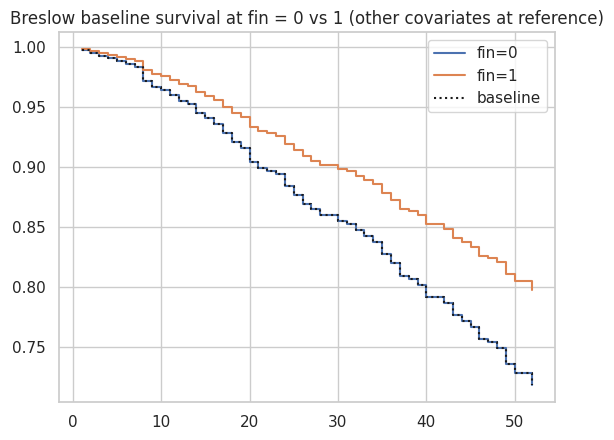

In [13]:
cph.plot_partial_effects_on_outcome(covariates="fin", values=[0, 1])
plt.title("Breslow baseline survival at fin = 0 vs 1 (other covariates at reference)")
plt.show()



---

**Lecture question**

If Cox doesn't specify the baseline hazard, how can `plot_partial_effects_on_outcome` draw a survival function? Mention Breslow.
What's the intuition behind Breslow?
Why not just use KM instead of Breslow with Cox?

**Answer**

After $\hat\beta$ is in hand, **Breslow** (or Efron) reconstructs $h_0$ as a discrete mass at each event time:
$$
d\hat\Lambda_0(t_i)=\frac{d_i}{\sum_{j\in R(t_i)} e^{x_j\hat\beta}}.
$$
Then $\hat S(t\mid x)=\exp\!\big(-e^{x\hat\beta}\hat\Lambda_0(t)\big)$. The plot is that curve at `fin=0` vs `fin=1` with other covariates at a reference. No parametric $h_0$ was assumed; a nonparametric baseline was *estimated*.

**Intuition.** The partial likelihood used only *who* failed, not *how much* baseline risk there was. Breslow asks: given those relative risks, how much baseline mass is needed to explain that $d_i$ people failed among the risk set? It is the Poisson MLE for the baseline jumps.

**Why not KM?** KM estimates $S(t)$ marginally, mixing all covariate patterns. Breslow estimates $S(t\mid x)$. Using KM "with Cox" would ignore $\hat\beta$. Using Breslow without covariates *does* reduce toward a Nelson–Aalen / KM pair.

**Criticism.** Breslow can be jumpy in small samples; Efron handles ties better. The plotted curve still assumes PH. If Schoenfeld plots are trending, the pretty `fin=0` vs `fin=1` curves are fiction in the tail.



## 7. PH diagnostics — Schoenfeld residuals

Scaled Schoenfeld residuals vs time (or rank / KM-transformed time): a trend means $\beta$ is not constant. `check_assumptions(..., show_plots=True)` is the lifelines version of an OLS residual suite.




   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age' failed the non-proportional test: p-value is 0.0007.

   Advice 1: the functional form of the variable 'age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'age' using pd.cut, and then specify it in `strata=['age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


2. Variable 'wexp' failed the non-proportional test: p-value is 0.0063.

   Advice: with so few unique values (only 2), you can include `strata=['wexp', ...]` in the call in
`.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a mome

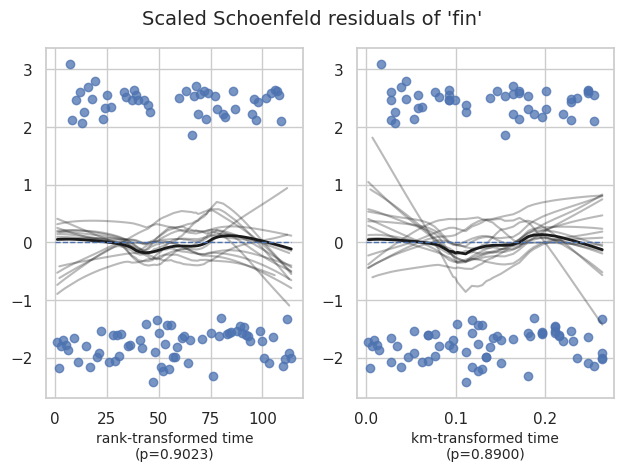

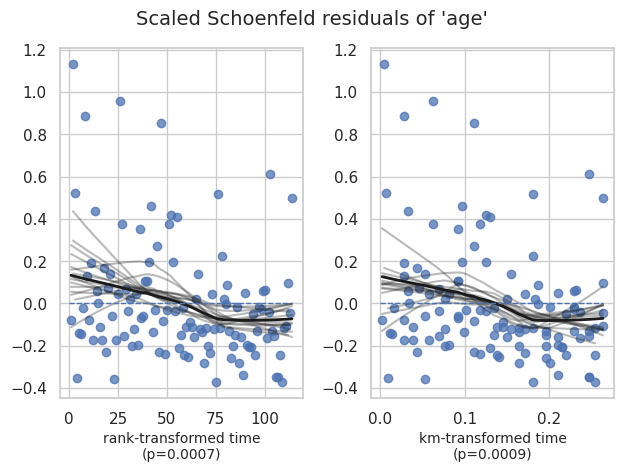

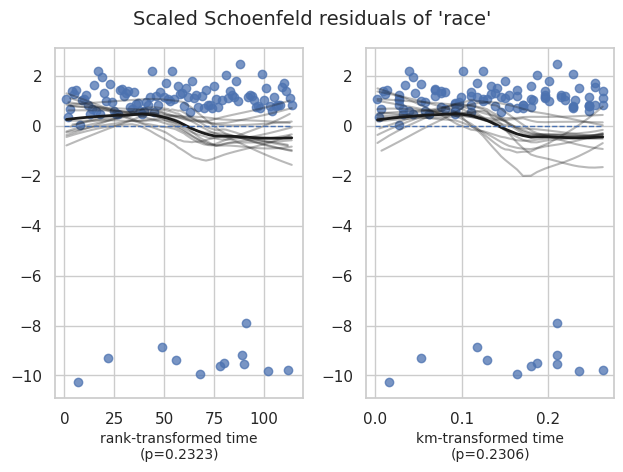

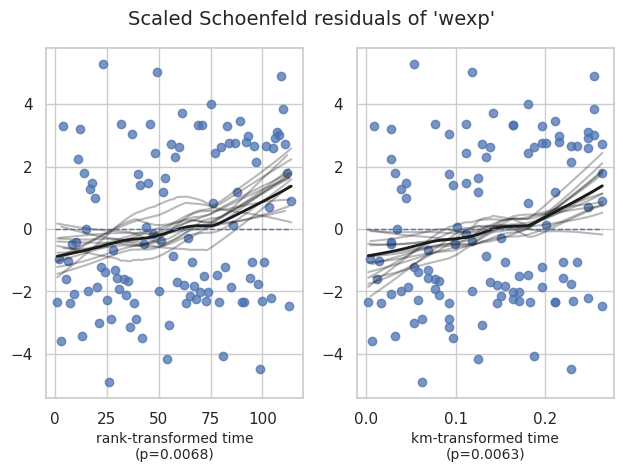

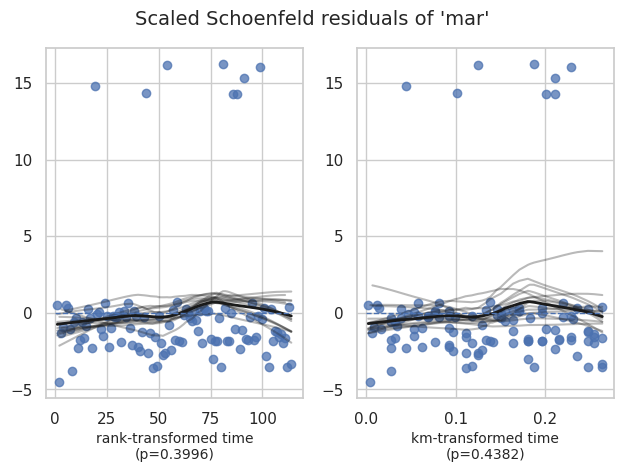

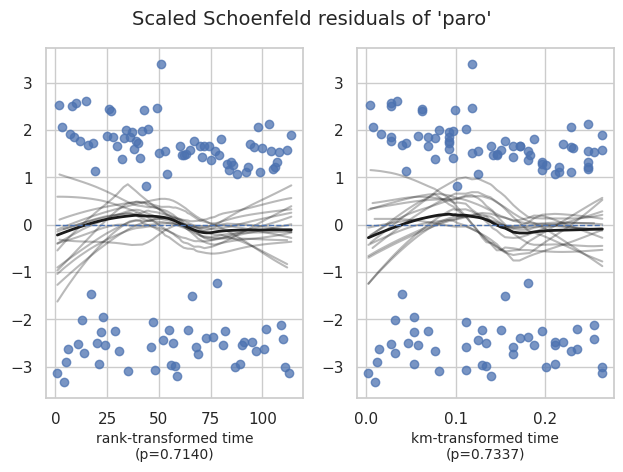

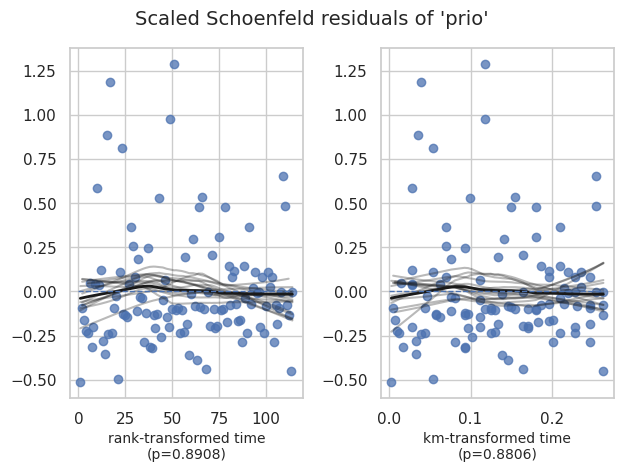

In [14]:
try:
    cph.check_assumptions(cox_df, show_plots=True, p_value_threshold=0.05)
except Exception as exc:
    print("check_assumptions finished with notes:\n", exc)



---

**Lecture question**

Analyze the assumption plots. What should I look for?
What are scaled Schoenfeld residuals? Rank-transformed time? KM-transformed time?
If PH is violated, what should I do?
Compare scikit-survival vs lifelines.

**Answer**

Look for a **flat** smoother of residual vs time, and a non-significant PH test per covariate. A trend means that covariate's $\beta$ is not constant: e.g. `fin` helps early and fades. Rank-transformed time and KM-transformed time are two x-axes that spread event times more evenly than raw week, so a late cluster of events does not dominate the scatter.

**Scaled Schoenfeld residual** for subject $i$ and covariate $k$ is a scaled difference between $x_{ik}$ and the risk-set weighted mean of $x_{\cdot k}$ at $i$'s event time. Under PH their expectation is 0 at every $t$; a plot vs time is a diagnostic for $\beta_k(t)$.

**If PH fails.** (1) Stratify on the offender (separate $h_0$ per `fin`, still estimate other $\beta$). (2) Interact with time or a spline of time. (3) Aalen additive model (effects add on the hazard, freely varying in $t$). (4) Accelerated failure time / parametric Weibull with covariates. (5) Split follow-up into epochs with different HRs. Do not only "robust SEs" and pretend the HR is a constant effect.

**lifelines vs scikit-survival.** lifelines: statistical reporting, `print_summary`, assumption plots, formula API, teaching. scikit-survival: sklearn pipelines, GBMs, survival SVMs, CV. Use lifelines to *understand* Rossi; use sksurv to *predict* with a messy feature pipeline. They are complements, not substitutes.

**Criticism.** `check_assumptions` p-values are many tests; a 0.04 on one covariate in a 7-covariate Cox is not a mandate to throw the model away. Combine plots, subject-matter, and effect size of the non-PH.



## 8. Tool map (lecture → this notebook)

| lecture tool | used here |
|---|---|
| `plot_lifetimes` | Rossi sample |
| `expon.fit` / `weibull_min.fit` | events-only MLE (biased under censoring) |
| log-likelihood compare | expon vs Weibull on events |
| `WeibullFitter` | proper censored Weibull |
| `scipy.stats.ecdf` | naive S(t) |
| `KaplanMeierFitter` | censored S(t) |
| `log(-log x)` figure | KM CI transform |
| `NelsonAalenFitter` | cumulative hazard |
| two KM curves | `fin` groups |
| `CoxPHFitter` | full Rossi covariates |
| `plot_partial_effects_on_outcome` | Breslow predictions |
| `check_assumptions` | Schoenfeld / PH |

